In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data = pd.read_csv("heart_disease.csv")

print("Original dataset shape:", data.shape)

display(data.head())

Original dataset shape: (302, 14)


,63.0,1.0,1.0.1,145.0,233.0,1.0.2,2.0,150.0,0.0,2.3,3.0,0.0.1,6.0,0
0,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
1,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
2,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
3,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
4,56.0,1.0,2.0,120.0,236.0,0.0,0.0,178.0,0.0,0.8,1.0,0.0,3.0,0


In [3]:
columns = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal",
    "num"
]

data = pd.read_csv(
    "heart_disease.csv",
    header=None,
    names=columns,
    na_values="?"
)

print("Original dataset shape:", data.shape)

display(data.head())

Original dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [4]:
print("Dataset Information:")
data.info()

print("\nDescriptive Statistics:")
display(data.describe().T)

print("\nFirst 5 rows:")
display(data.head())

print("\nTarget distribution:")
display(data["num"].value_counts(dropna=False))

print("\nTarget distribution in percentage:")
display(
    (data["num"].value_counts(normalize=True) * 100).round(2)
)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2



First 5 rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



Target distribution:


num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


Target distribution in percentage:


num
0    54.13
1    18.15
2    11.88
3    11.55
4     4.29
Name: proportion, dtype: float64

In [5]:
# Convert all columns to numeric
for column in data.columns:
    data[column] = pd.to_numeric(data[column], errors="coerce")

df = data.copy()

print("Missing values:")
display(df.isnull().sum())

print("\nDataset shape:")
print(df.shape)

Missing values:


age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64


Dataset shape:
(303, 14)


In [6]:
target_column = "num"

df = df.dropna(subset=[target_column]).copy()

print("Dataset shape after removing missing target values:")
print(df.shape)

Dataset shape after removing missing target values:
(303, 14)


In [7]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)

Number of duplicate rows: 0
Dataset shape after removing duplicates: (303, 14)


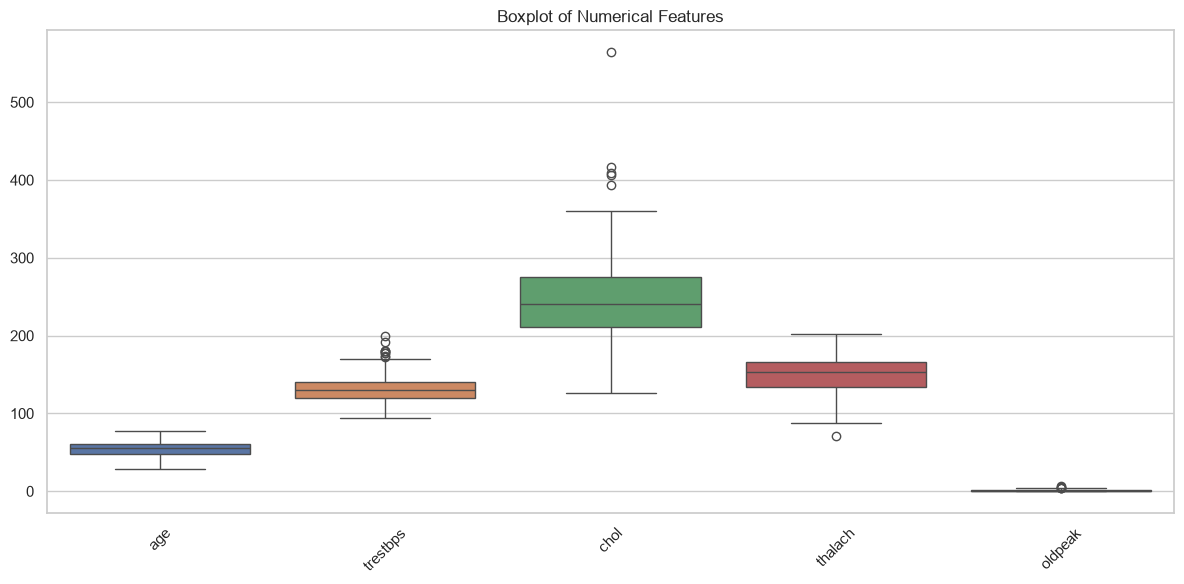

In [8]:
numerical_columns = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

plt.figure(figsize=(12, 6))

sns.boxplot(data=df[numerical_columns])

plt.title("Boxplot of Numerical Features")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [9]:
for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(column, ":", len(outliers), "possible outliers")

age : 0 possible outliers
trestbps : 9 possible outliers
chol : 5 possible outliers
thalach : 1 possible outliers
oldpeak : 5 possible outliers


In [10]:
df["target"] = df["num"].apply(
    lambda x: 1 if x > 0 else 0
)

df = df.drop(columns=["num"])

print("New target distribution:")

display(df["target"].value_counts())

print("\nTarget percentage:")

display(
    (df["target"].value_counts(normalize=True) * 100).round(2)
)

New target distribution:


target
0    164
1    139
Name: count, dtype: int64


Target percentage:


target
0    54.13
1    45.87
Name: proportion, dtype: float64

In [11]:
X = df.drop(columns=["target"])
y = df["target"]
print("Independent variables (X):", X.shape)
print("Dependent variable (y):", y.shape)
print("\nTarget classes:")
print(y.value_counts())

Independent variables (X): (303, 13)
Dependent variable (y): (303,)

Target classes:
target
0    164
1    139
Name: count, dtype: int64


In [12]:
categorical_columns = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

numerical_columns = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

print("Categorical columns:")
print(categorical_columns)
print("\nNumerical columns:")
print(numerical_columns)

Categorical columns:
['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

Numerical columns:
['age', 'trestbps', 'chol', 'thalach', 'oldpeak']


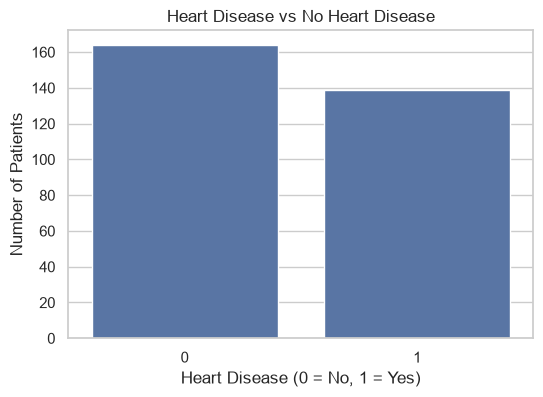

In [13]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="target")
plt.title("Heart Disease vs No Heart Disease")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")
plt.show()

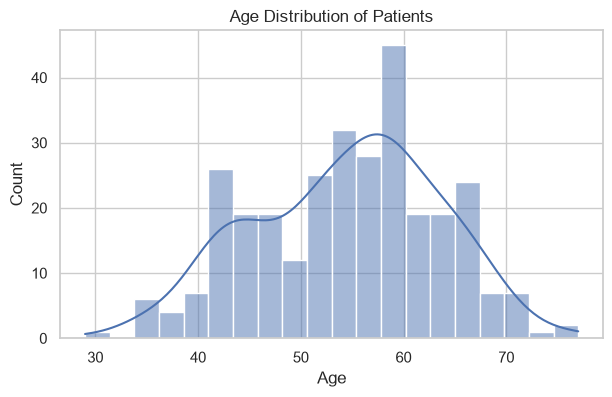

In [14]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="age", bins=20, kde=True)
plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

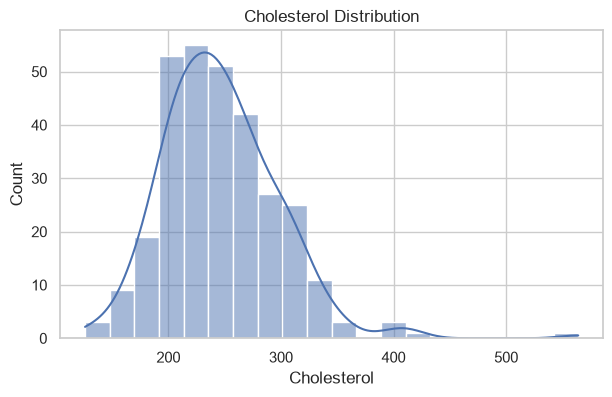

In [15]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="chol", bins=20, kde=True)
plt.title("Cholesterol Distribution")
plt.xlabel("Cholesterol")
plt.ylabel("Count")
plt.show()

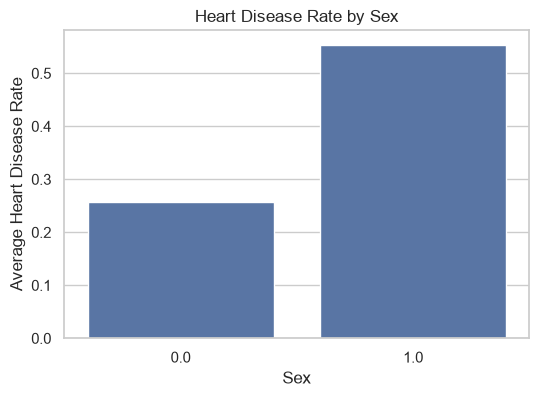

In [17]:
plt.figure(figsize=(6, 4))

sns.barplot(
    data=df,
    x="sex",
    y="target",
    errorbar=None
)

plt.title("Heart Disease Rate by Sex")
plt.xlabel("Sex")
plt.ylabel("Average Heart Disease Rate")
plt.show()

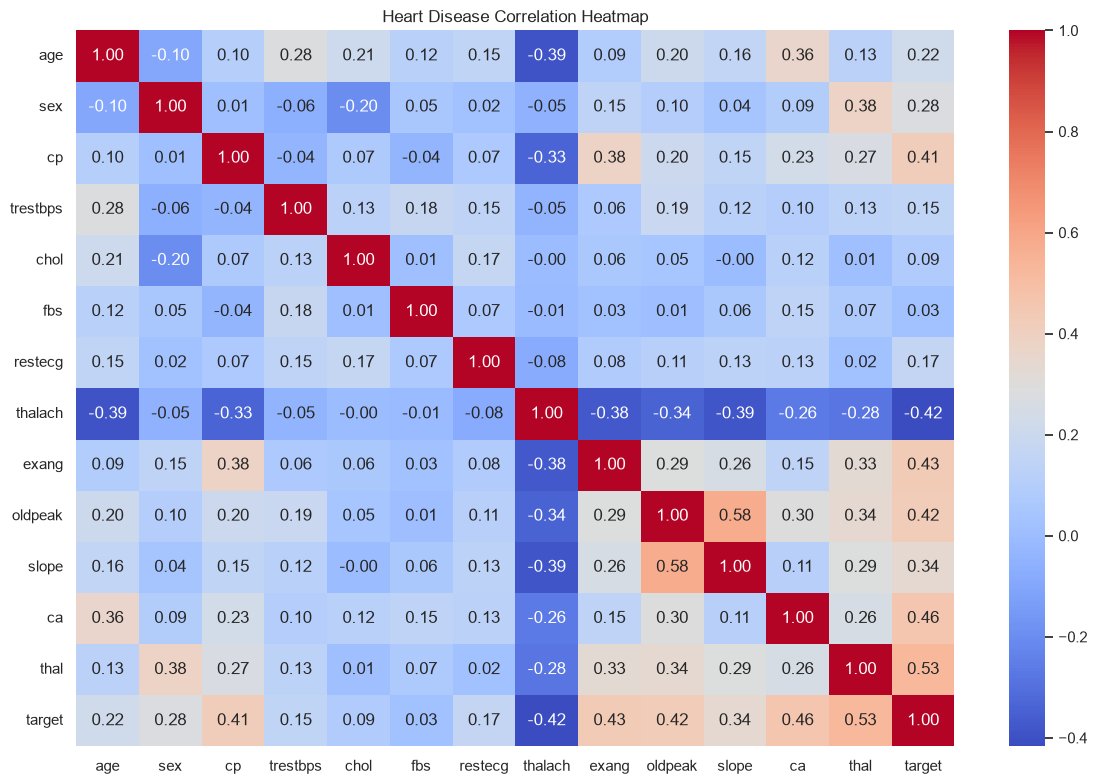

In [18]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Heart Disease Correlation Heatmap")
plt.tight_layout()
plt.show()

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts())
print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (242, 13)
Testing features: (61, 13)

Training target distribution:
target
0    131
1    111
Name: count, dtype: int64

Testing target distribution:
target
0    33
1    28
Name: count, dtype: int64


In [20]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [22]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [23]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numerical_columns),
        ("categorical", categorical_transformer, categorical_columns)
    ]
)

print("Preprocessing completed!")

Preprocessing completed!


In [24]:
selector = SelectKBest(
    score_func=f_classif,
    k=10
)

print("Feature selection method: SelectKBest")

print("Number of selected features: 10")

Feature selection method: SelectKBest
Number of selected features: 10


In [25]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5
    )
}

print("Models selected successfully!")

Models selected successfully!


In [26]:
scores = []

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("feature_selection", selector),
        ("classifier", model)
    ])

    # Train the model
    pipeline.fit(X_train, y_train)

    # Make predictions
    y_pred = pipeline.predict(X_test)

    # Probability prediction for ROC-AUC
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    roc_auc = roc_auc_score(y_test, y_prob)

    scores.append({
        "Model": name,
        "Accuracy": round(accuracy, 4),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1 Score": round(f1, 4),
        "ROC-AUC": round(roc_auc, 4)
    })

    trained_models[name] = pipeline

# Display results
results_df = pd.DataFrame(scores)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.9180,0.8966,0.9286,0.9123,0.9589
3,K-Nearest Neighbors,0.9016,0.8438,0.9643,0.9000,0.9497
2,Random Forest,0.8033,0.7500,0.8571,0.8000,0.9232
1,Decision Tree,0.7541,0.6970,0.8214,0.7541,0.7592
